# 04 - Đánh giá & Trực quan hóa

Giai đoạn 5-6 của kế hoạch: đánh giá và so sánh 3 mô hình (Precision/Recall/F1/ROC-AUC/PR-AUC/Confusion Matrix), sau đó trực quan hóa kết quả.

Vì dữ liệu mất cân bằng nặng (~0.17% gian lận), **KHÔNG dùng Accuracy** để đánh giá.

Notebook này gọi trực tiếp các hàm trong `src/evaluate.py` và `src/visualize.py`.

In [1]:
import os
import sys

os.environ.setdefault("JAVA_HOME", r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot")
os.environ.setdefault("HADOOP_HOME", r"D:\fraud-detection\hadoop")
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]

sys.path.insert(0, os.path.abspath("../src"))

from evaluate import run_evaluation

comparison_df = run_evaluation()
comparison_df

[Evaluate] Logistic Regression: ngưỡng phân loại = 0.7589



=== Logistic Regression ===
Precision: 0.8033 | Recall: 0.4579 | F1: 0.5833
ROC-AUC: 0.9790 | PR-AUC: 0.6493
Confusion matrix -> TN=85205 FP=12 FN=58 TP=49


[Evaluate] Random Forest: ngưỡng phân loại = 0.5594

=== Random Forest ===
Precision: 0.9494 | Recall: 0.7009 | F1: 0.8065
ROC-AUC: 0.9574 | PR-AUC: 0.8122
Confusion matrix -> TN=85213 FP=4 FN=32 TP=75



=== Isolation Forest ===
Precision: 0.0544 | Recall: 0.4953 | F1: 0.0980
ROC-AUC: 0.9366 | PR-AUC: 0.0351
Confusion matrix -> TN=84295 FP=922 FN=54 TP=53

[Evaluate] Bảng so sánh 3 mô hình đã lưu -> D:\fraud-detection\reports\metrics_comparison.csv
              model  precision   recall  f1_score  roc_auc   pr_auc    tn  fp  fn  tp
Logistic Regression   0.803279 0.457944  0.583333 0.979034 0.649313 85205  12  58  49
      Random Forest   0.949367 0.700935  0.806452 0.957412 0.812203 85213   4  32  75
   Isolation Forest   0.054359 0.495327  0.097967 0.936619 0.035113 84295 922  54  53


,model,precision,recall,f1_score,roc_auc,pr_auc,tn,fp,fn,tp
0,Logistic Regression,0.803279,0.457944,0.583333,0.979034,0.649313,85205,12,58,49
1,Random Forest,0.949367,0.700935,0.806452,0.957412,0.812203,85213,4,32,75
2,Isolation Forest,0.054359,0.495327,0.097967,0.936619,0.035113,84295,922,54,53


`run_evaluation()` tự động đọc `models/thresholds.json` (ngưỡng phân loại đã tối ưu từ
`tune_models.py`) nếu có, để tính Precision/Recall/F1 - nếu chưa chạy tune_models.py, dùng
ngưỡng mặc định 0.5.

Bảng so sánh trên cũng được lưu ra `reports/metrics_comparison.csv`.

## Trực quan hóa

`run_visualization()` xuất 5 biểu đồ vào `reports/figures/`:
1. Phân phối giao dịch bình thường vs gian lận
2. PCA 2D minh họa vùng anomaly do Isolation Forest phát hiện
3. Confusion matrix heatmap từng mô hình
4. So sánh Precision/Recall/F1/ROC-AUC/PR-AUC giữa 3 mô hình
5. Giao dịch nghi vấn theo thời gian/số tiền

In [2]:
from visualize import run_visualization

run_visualization()

[Viz] Đã lưu class_distribution.png


[Viz] Đã lưu pca_anomaly.png


[Viz] Đã lưu confusion_matrices.png


[Viz] Đã lưu metrics_comparison.png


[Viz] Đã lưu suspicious_transactions.png


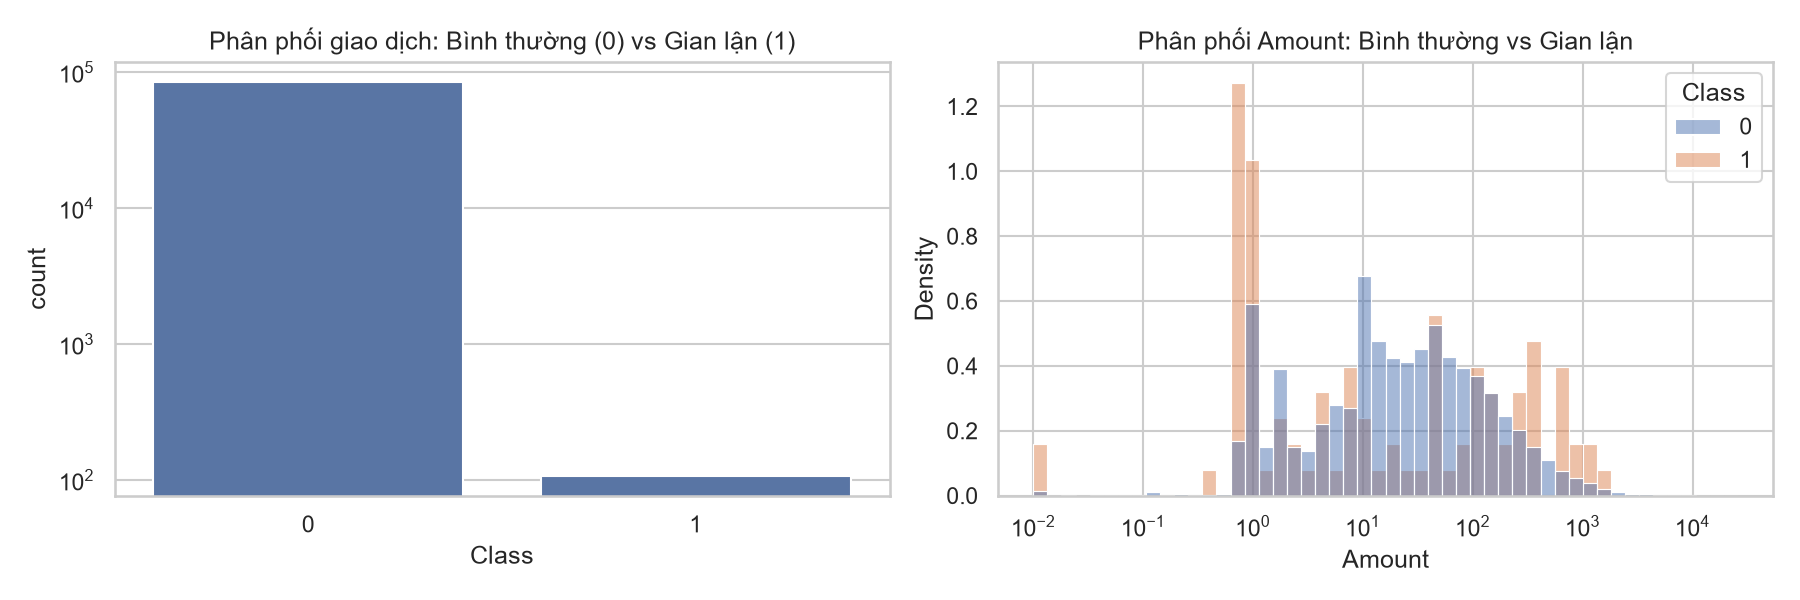

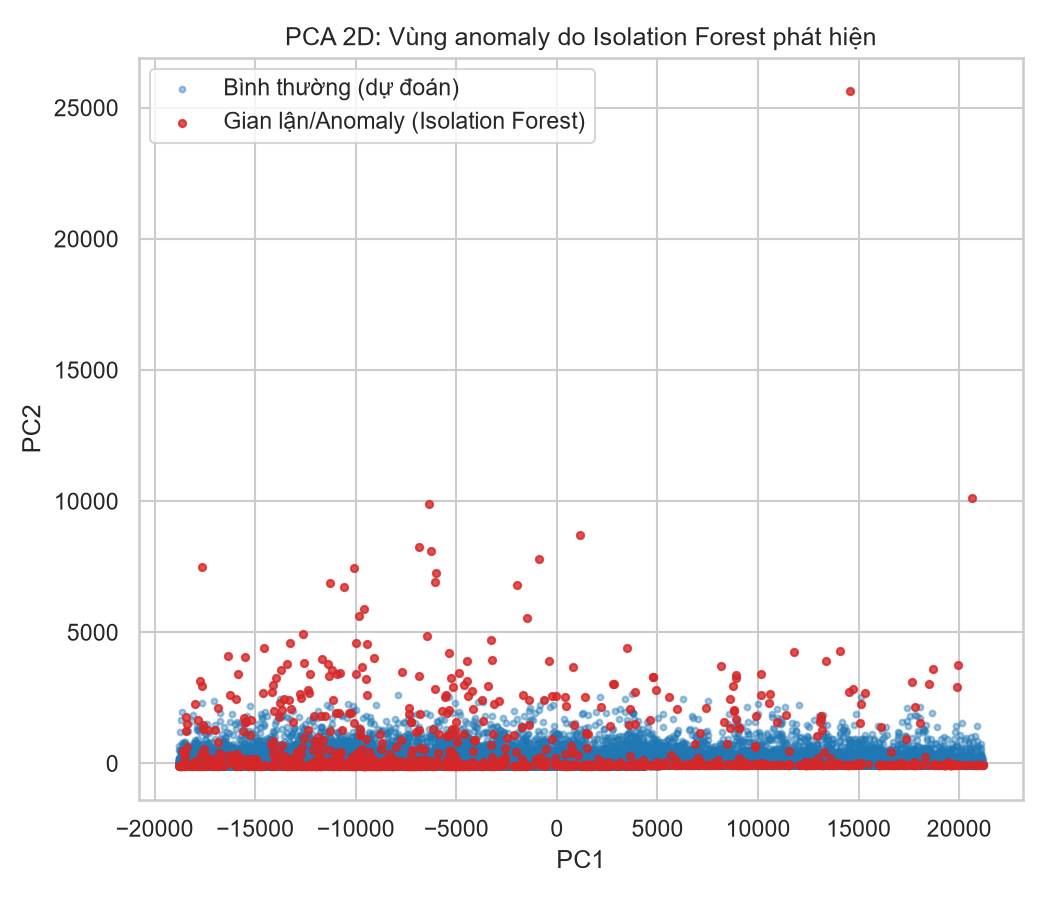

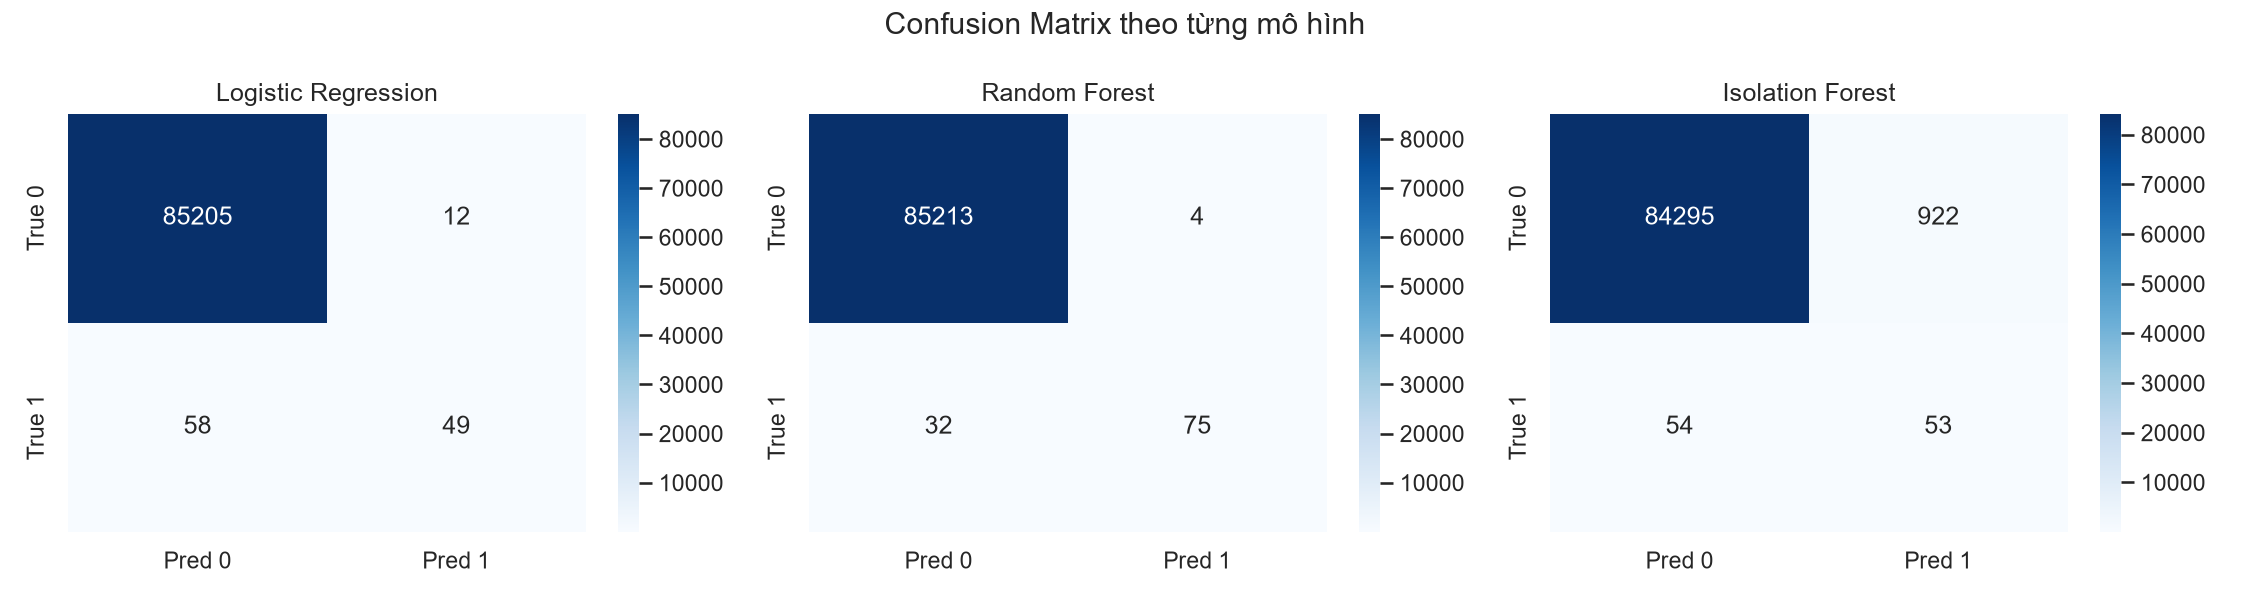

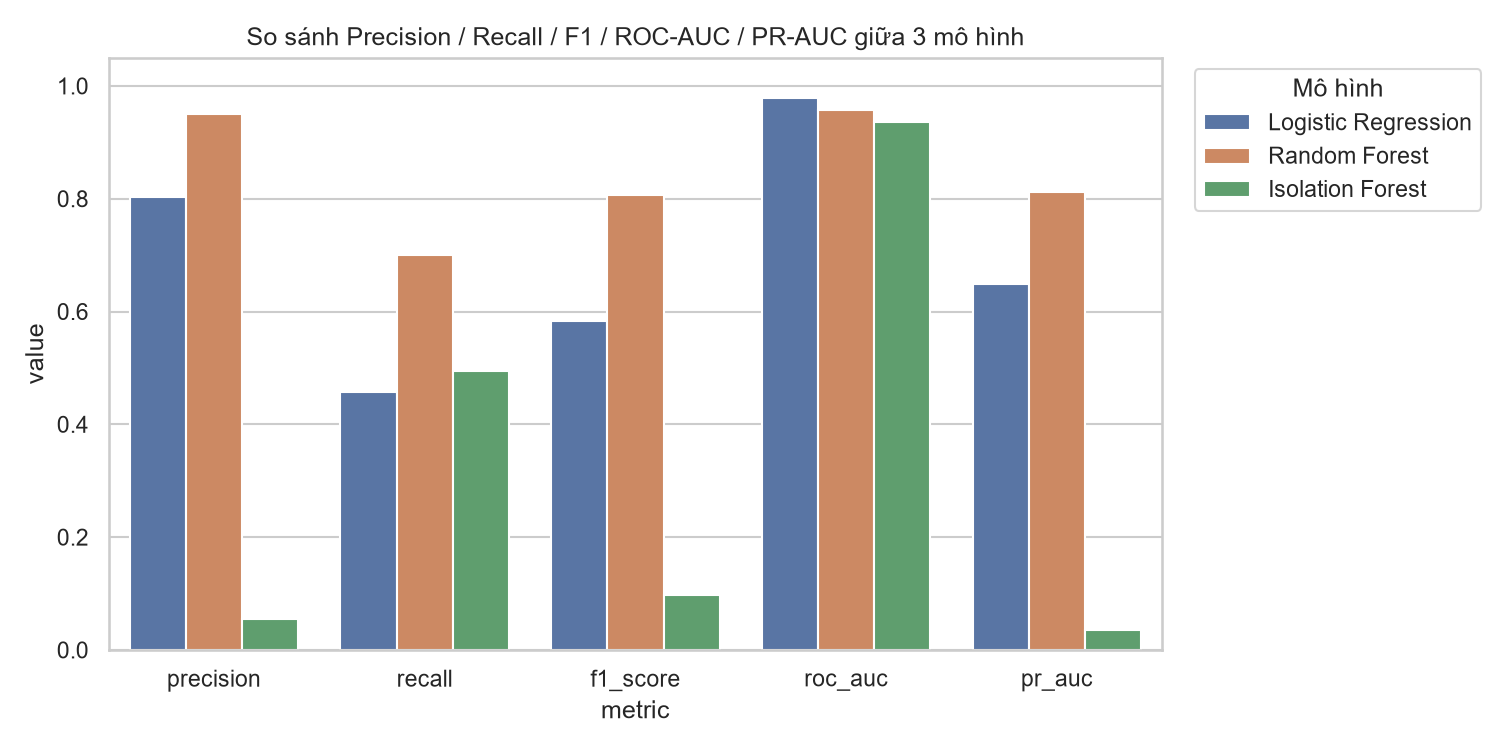

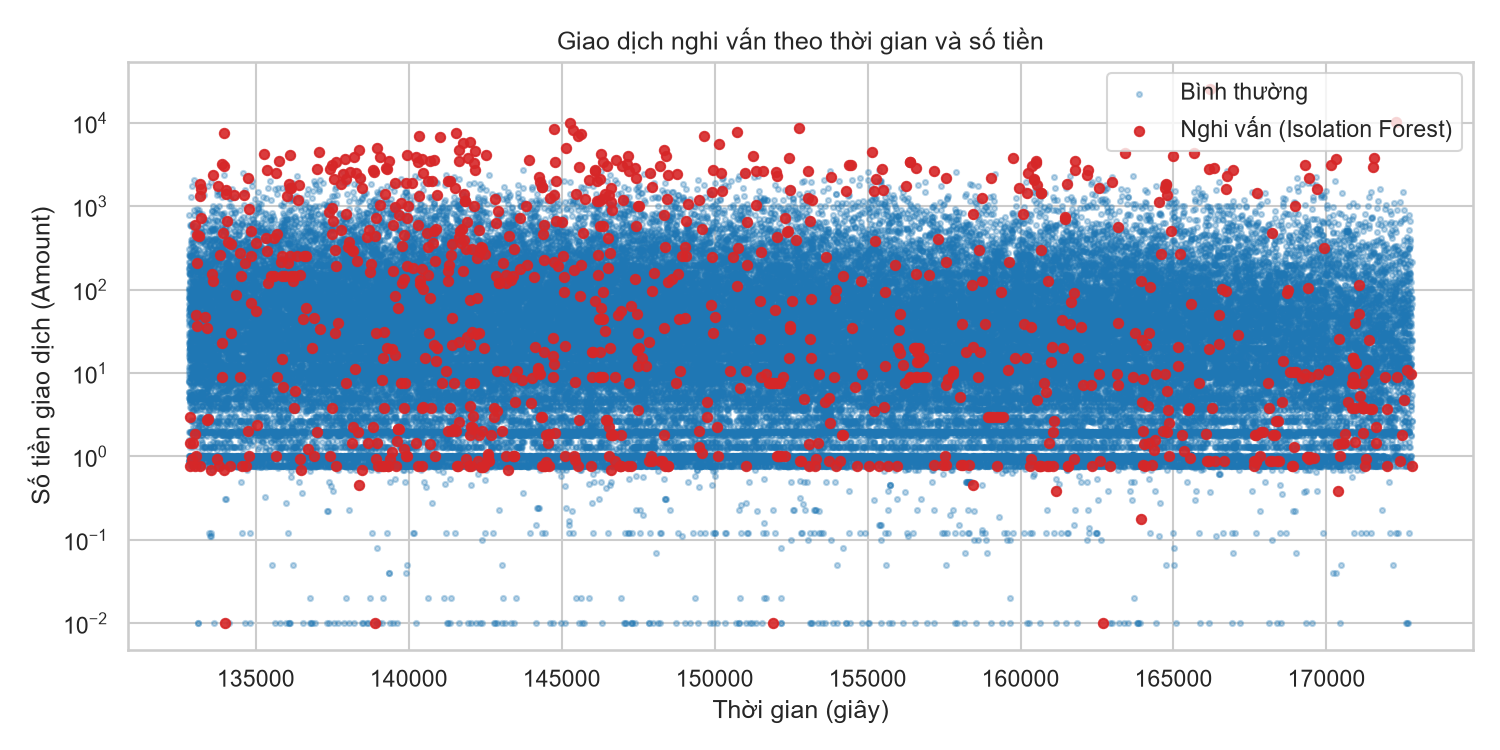

In [3]:
from IPython.display import Image, display
from config import FIGURES_DIR

for name in [
    "class_distribution.png",
    "pca_anomaly.png",
    "confusion_matrices.png",
    "metrics_comparison.png",
    "suspicious_transactions.png",
]:
    display(Image(filename=str(FIGURES_DIR / name)))

## Nhận xét kết quả

- **Random Forest** cho kết quả cân bằng nhất (Precision/Recall/F1 cao nhất trong 3 mô hình).
- **Logistic Regression** dễ giải thích, sau khi tối ưu ngưỡng phân loại (threshold) cho
  Precision cải thiện đáng kể so với ngưỡng mặc định 0.5.
- **Isolation Forest** (unsupervised) có Precision/PR-AUC thấp hơn hẳn - đây là hạn chế đã biết
  của phương pháp không dùng nhãn: nó phát hiện điểm bị "cô lập" trong toàn bộ không gian đặc
  trưng, không nhất thiết trùng với các giao dịch gian lận thật.